# 03. Model selection

This notebook reads the cross-validation results of `python -m hatari.models.selection`, about six minutes, and of `python -m hatari.models.intervals`, and applies the selection rule of `docs/04_modelling_protocol.md`. The rule and the candidates were committed before any model was trained. The test set is not used.

In [1]:
import subprocess
import sys
from pathlib import Path

import pandas as pd
from IPython.display import display

ROOT = Path.cwd().parent
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)


def run_tests(*files):
    result = subprocess.run([sys.executable, "-m", "pytest", "-q", "--color=no", *files], cwd=ROOT, capture_output=True, text=True)
    print(result.stdout.strip().splitlines()[-1])

## 1. Unit tests

In [2]:
run_tests("tests/test_selection.py", "tests/test_uncertainty.py", "tests/test_preprocessing.py")

27 passed, 12 warnings in 17.20s


## 2. Every configuration

In [3]:
from hatari.models.candidates import all_candidates
from hatari.models.selection import select

results = pd.read_csv(ROOT / "reports" / "cross_validation.csv")
view = results.pivot_table(index="candidate", columns="language", values=["precision", "recall", "f1"])
display(view.round(3).sort_values(("f1", "en"), ascending=False))

f1        precision        recall       
language                    en     fr        en     fr     en     fr
candidate                                                           
SVM-char_normalize_C10   0.975  0.828     0.993  0.707  0.958  1.000
SVM-char_normalize_C0.1  0.975  0.800     0.986  0.667  0.964  1.000
SVM-char_normalize_C1    0.974  0.824     0.990  0.700  0.958  1.000
LR-char_normalize_C10    0.973  0.814     0.984  0.686  0.963  1.000
SVM-char_mask_C10        0.972  0.833     0.984  0.714  0.959  1.000
SVM-char_mask_C1         0.970  0.819     0.980  0.693  0.960  1.000
LR-char_normalize_C1     0.969  0.800     0.977  0.667  0.962  1.000
LR-char_mask_C10         0.969  0.814     0.977  0.686  0.962  1.000
SVM-char_mask_C0.1       0.969  0.805     0.975  0.673  0.963  1.000
SVM_mask_C10             0.968  0.824     0.978  0.700  0.958  1.000
LR-char_mask_C1          0.966  0.805     0.971  0.673  0.962  1.000
SVM_mask_C1              0.966  0.809     0.973  0.680  0.958  1.000
LR_mask_C10              0.962  0.805     0.967  0.673  0.957  1.000
SVM_mask_C0.1            0.961  0.805     0.966  0.673  0.956  1.000
LR-char_mask_C0.1        0.961  0.800     0.972  0.667  0.951  1.000
LR-char_normalize_C0.1   0.958  0.786     0.961  0.648  0.954  1.000
LR_mask_C1               0.958  0.805     0.958  0.673  0.957  1.000
SVM_normalize_C1         0.954  0.809     0.970  0.680  0.938  1.000
SVM_normalize_C10        0.953  0.828     0.976  0.707  0.931  1.000
LR_normalize_C10         0.951  0.809     0.958  0.680  0.944  1.000
SVM_normalize_C0.1       0.943  0.800     0.943  0.667  0.944  1.000
LR_normalize_C1          0.942  0.800     0.936  0.667  0.947  1.000
LR_mask_C0.1             0.938  0.810     0.949  0.694  0.927  0.971
LR_normalize_C0.1        0.914  0.809     0.917  0.680  0.912  1.000
NB_mask                  0.820  0.833     0.998  0.714  0.695  1.000
NB_normalize             0.774  0.833     0.998  0.714  0.633  1.000

## 3. Selection rule

In [4]:
english = results[results["language"] == "en"]
best = english["f1"].max()
tied = english[english["f1"] >= best - 0.01]
print("best English F1:", round(best, 4), "| configurations within 0.01:", len(tied))
print("best recall among them:", round(tied["recall"].max(), 4))
print("selected:", select(results, all_candidates()).name)

best English F1: 0.9752 | configurations within 0.01: 12
best recall among them: 0.9641
selected: SVM_mask_C1


**Finding.** Twelve configurations are within 0.01 of the best F1 and within 0.01 of the best recall. The simplest of them, in the order of the protocol, is SVM_mask_C1.

## 4. Confidence intervals and paired differences

In [5]:
intervals = pd.read_csv(ROOT / "reports" / "cv_intervals.csv")
display(intervals.round(3))

,candidate,messages,groups,precision_low,precision_high,recall_low,recall_high,f1_low,f1_high,f1_minus_selected,difference_low,difference_high
0,SVM_mask_C1,4812,4700,0.961,0.984,0.944,0.971,0.956,0.974,NaN,NaN,NaN
1,SVM-char_normalize_C0.1,4812,4700,0.978,0.994,0.951,0.976,0.967,0.983,0.010,0.002,0.016
2,LR_mask_C10,4812,4700,0.954,0.979,0.943,0.970,0.952,0.972,-0.004,-0.007,0.000
3,NB_mask,4812,4700,0.994,1.000,0.661,0.730,0.795,0.844,-0.146,-0.170,-0.123


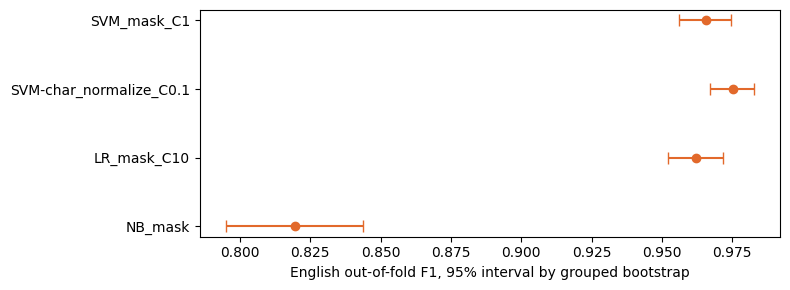

In [6]:
import matplotlib.pyplot as plt

f1 = english.set_index("candidate").loc[intervals["candidate"], "f1"]
figure, axis = plt.subplots(figsize=(8, 3))
axis.errorbar(f1.to_numpy(), range(len(f1)), xerr=[f1.to_numpy() - intervals["f1_low"], intervals["f1_high"] - f1.to_numpy()],
              fmt="o", color="#E2692B", capsize=4)
axis.set_yticks(range(len(f1)), intervals["candidate"])
axis.set_xlabel("English out-of-fold F1, 95% interval by grouped bootstrap")
axis.invert_yaxis()
plt.tight_layout()
plt.show()

**Findings**

- The character n-gram SVM is significantly better than the selected model, by 0.0096 of F1, with an interval of 0.0025 to 0.0164. The fixed margin of 0.01 of the protocol was too wide for these data.
- The selected model is kept, since the selection was frozen before the test evaluation. The comparison is left to a next version, on new data.
- Naive Bayes is far behind, mostly through missed suspicious messages at its default threshold.

## 5. French texts

In [7]:
french = results[results["language"] == "fr"].set_index("candidate")
display(french.loc[intervals["candidate"], ["precision", "recall", "f1", "true_negatives", "false_positives"]])

,precision,recall,f1,true_negatives,false_positives
candidate,,,,,
SVM_mask_C1,0.6796,1.0,0.8092,14,33
SVM-char_normalize_C0.1,0.6667,1.0,0.8000,12,35
LR_mask_C10,0.6731,1.0,0.8046,13,34
NB_mask,0.7143,1.0,0.8333,19,28


**Finding.** Every configuration detects all 70 French suspicious texts but flags most of the 47 legitimate ones, between 28 and 35. The French training data has too few legitimate families.